# Project 11: Handwritten Digit Classification Using CNN

**Name:** Syahrul

**Objective:** Build a basic Convolutional Neural Network (CNN) to classify handwritten digits from the MNIST dataset.

## Introduction

MNIST contains grayscale images of handwritten digits from 0 to 9. Each image is 28 × 28 pixels. A CNN learns image features through convolution and pooling layers, then predicts which digit appears in each image.

## Task 1: Load and Preprocess the MNIST Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, ConfusionMatrixDisplay

import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

np.random.seed(42)
tf.random.set_seed(42)

(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)
print("Number of classes:", len(np.unique(y_train)))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)
Number of classes: 10


In [2]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

print("Preprocessed training shape:", X_train.shape)
print("Preprocessed testing shape:", X_test.shape)

Preprocessed training shape: (60000, 28, 28, 1)
Preprocessed testing shape: (10000, 28, 28, 1)


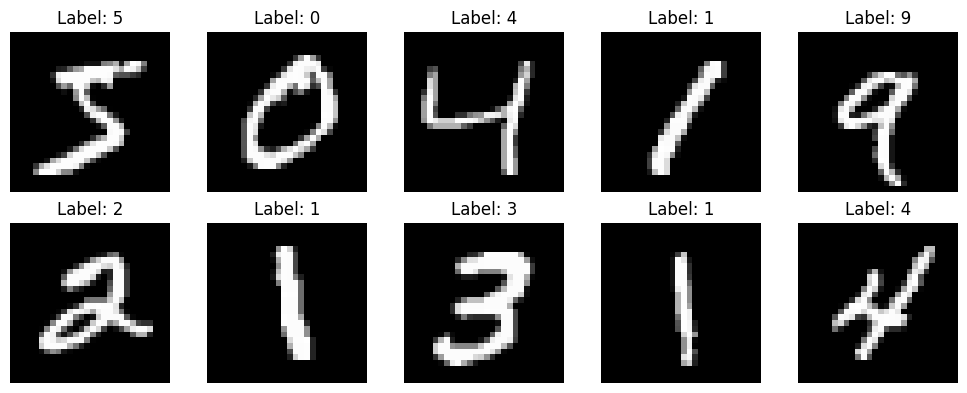

In [3]:
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i].squeeze(), cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## Task 2: Build and Train the CNN Model

In [4]:
model = Sequential([
    Conv2D(32, (3, 3), activation="relu", input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - accuracy: 0.8933 - loss: 0.3467 - val_accuracy: 0.9815 - val_loss: 0.0661
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9691 - loss: 0.1058 - val_accuracy: 0.9857 - val_loss: 0.0478
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9770 - loss: 0.0774 - val_accuracy: 0.9885 - val_loss: 0.0419
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9812 - loss: 0.0620 - val_accuracy: 0.9900 - val_loss: 0.0353
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9838 - loss: 0.0530 - val_accuracy: 0.9885 - val_loss: 0.0379


In [6]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Loss: {test_loss:.4f}")

Test Accuracy: 0.9887
Test Loss: 0.0323


## Training Performance

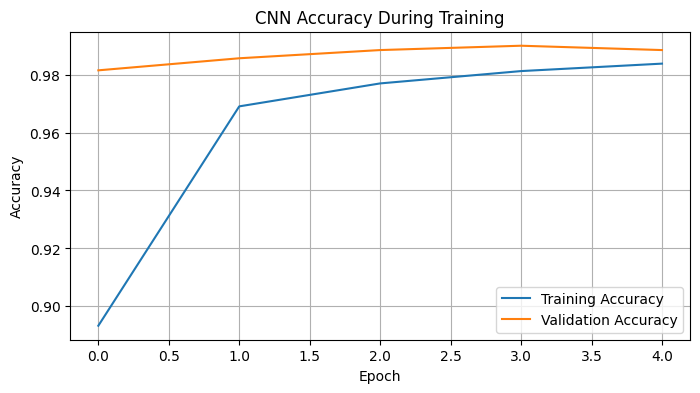

In [7]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Accuracy During Training")
plt.legend()
plt.grid(True)
plt.show()

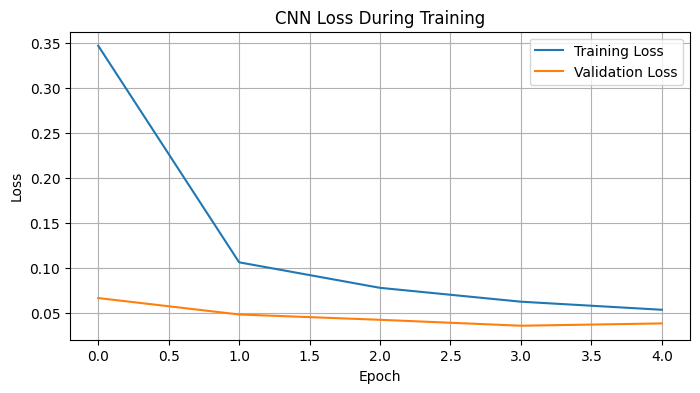

In [8]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Loss During Training")
plt.legend()
plt.grid(True)
plt.show()

## Task 3: Confusion Matrix and Classification Report

Test Accuracy: 0.9887


,0,1,2,3,4,5,6,7,8,9
0,966,0,1,0,0,1,7,3,2,0
1,0,1133,0,1,0,0,1,0,0,0
2,1,1,1019,0,1,0,0,6,3,1
3,0,0,2,999,0,5,0,1,3,0
4,0,0,0,0,980,0,1,0,0,1
5,1,0,1,5,0,882,1,0,1,1
6,0,2,1,0,1,5,949,0,0,0
7,0,3,5,3,0,1,0,1010,2,4
8,1,0,2,1,0,0,0,2,966,2
9,2,3,0,0,8,5,0,0,8,983


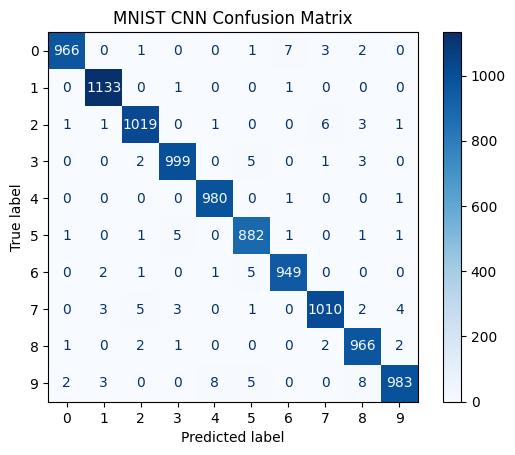

Classification Report:
              precision    recall  f1-score   support

           0     0.9949    0.9857    0.9903       980
           1     0.9921    0.9982    0.9952      1135
           2     0.9884    0.9874    0.9879      1032
           3     0.9901    0.9891    0.9896      1010
           4     0.9899    0.9980    0.9939       982
           5     0.9811    0.9888    0.9849       892
           6     0.9896    0.9906    0.9901       958
           7     0.9883    0.9825    0.9854      1028
           8     0.9807    0.9918    0.9862       974
           9     0.9909    0.9742    0.9825      1009

    accuracy                         0.9887     10000
   macro avg     0.9886    0.9886    0.9886     10000
weighted avg     0.9887    0.9887    0.9887     10000



In [9]:
y_probabilities = model.predict(X_test, verbose=0)
y_predictions = np.argmax(y_probabilities, axis=1)

test_accuracy = accuracy_score(y_test, y_predictions)
print(f"Test Accuracy: {test_accuracy:.4f}")

cm = confusion_matrix(y_test, y_predictions)
display(pd.DataFrame(cm, index=range(10), columns=range(10)))

confusion_display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=range(10))
confusion_display.plot(cmap="Blues", values_format="d")
plt.title("MNIST CNN Confusion Matrix")
plt.show()

print("Classification Report:")
print(classification_report(y_test, y_predictions, digits=4))

## Sample Predictions

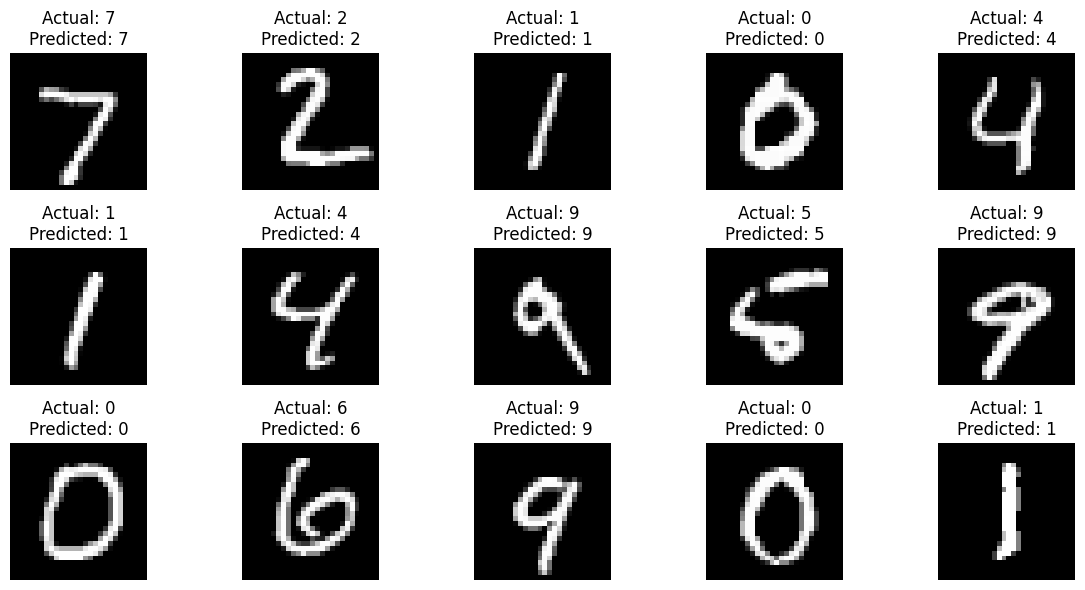

In [10]:
plt.figure(figsize=(12, 6))

for i in range(15):
    plt.subplot(3, 5, i + 1)
    image = X_test[i].squeeze()
    actual = y_test[i]
    predicted = y_predictions[i]
    plt.imshow(image, cmap="gray")
    plt.title(f"Actual: {actual}\nPredicted: {predicted}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## Observation

The confusion matrix shows how many images from each actual digit class were predicted as each digit. Values on the main diagonal are correct predictions, while values outside the diagonal are misclassifications. The classification report provides precision, recall, and F1-score for each digit. Use the values produced by your run to identify which digits were classified well and which were confused.

## Result

A CNN was trained on the MNIST handwritten digit dataset. Its performance was evaluated using test accuracy, a confusion matrix, a classification report, and sample predictions.

## Conclusion

This project demonstrated how a CNN can classify handwritten digits. Convolutional layers learn image features, pooling layers reduce feature-map size, and dense layers use the learned features to predict one of the ten digit classes. The evaluation outputs help show the model's strengths and common mistakes.